In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from itertools import combinations

In [2]:
#Load in the data
df = pd.read_csv("star_classification.csv", dtype={"obj_ID": "string"})
ognrow = len(df)
filters = ["u", "g", "r", "i", "z"]
filtersname = {}
for key, value in zip(filters, ["Ultraviolet", "Green", "Red", "Near Infrared", "Infrared"]):
    filtersname[key] = value
print(ognrow,"\n",filters,"\n",filtersname)

100000 
 ['u', 'g', 'r', 'i', 'z'] 
 {'u': 'Ultraviolet', 'g': 'Green', 'r': 'Red', 'i': 'Near Infrared', 'z': 'Infrared'}


In [3]:
#Inspect the data
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1237660961327743232,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1237664879951151360,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1237660961330430208,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1237663478724297984,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1237680272041378048,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [4]:
#Check amount of rows and columns
df.shape

(100000, 18)

In [5]:
print("There are "+str(len(df))+" rows in this dataset.")

There are 100000 rows in this dataset.


In [6]:
#See what all objects are in the dataset
df["class"].value_counts()

class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64

In [7]:
#Remove QSOs as this is between stars and galaxies
df = df[df["class"].isin(["STAR", "GALAXY"])]
df["class"].value_counts()

class
GALAXY    59445
STAR      21594
Name: count, dtype: int64

In [8]:
#Remove missing values
for x in filters:
    df = df[df[x].isna() == False]

In [9]:
#Check if there are random values
df.min()
#There seem to be filters set to -9999.0 which indicate missing values

obj_ID           1.237646794381e+18
alpha                      0.005528
delta                    -18.785328
u                           -9999.0
g                           -9999.0
r                           9.82207
i                          9.469903
z                           -9999.0
run_ID                          109
rerun_ID                        301
cam_col                           1
field_ID                         11
spec_obj_ID    299519089380976640.0
class                        GALAXY
redshift                  -0.009971
plate                           266
MJD                           51608
fiber_ID                          1
dtype: object

In [10]:
#Remove the -9999s which indicate missing values
for x in filters:
    df = df[df[x] != -9999.0]
print("The original dataset started at "+str(ognrow)+" records, now in the cleaned dataset we have "+str(len(df))+ " records.")
#There seems to only be one record with messed up values

The original dataset started at 100000 records, now in the cleaned dataset we have 81038 records.


In [11]:
#Seperate tables for galaxies and stars for preliminary graphs
staronly = df[df["class"] == "STAR"]
galaxyonly = df[df["class"] == "GALAXY"]

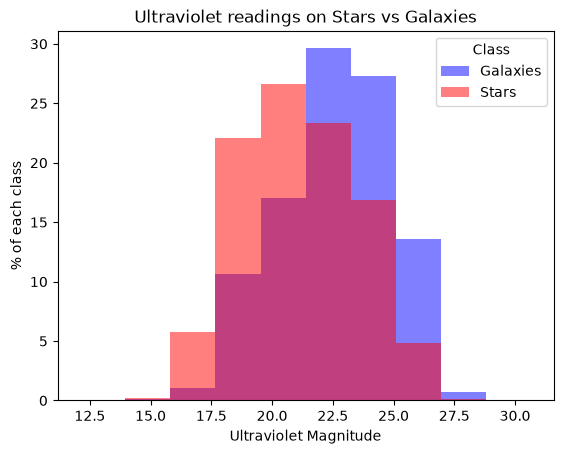

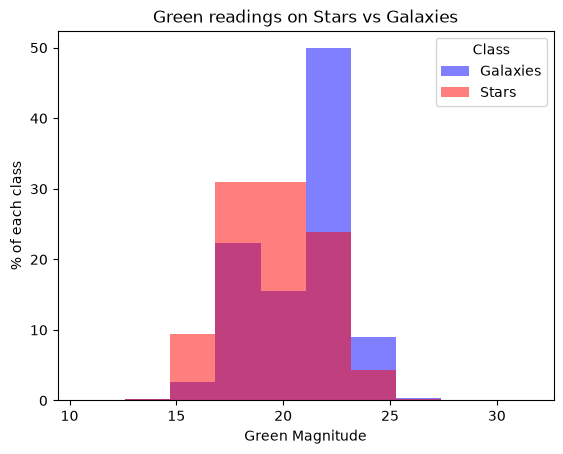

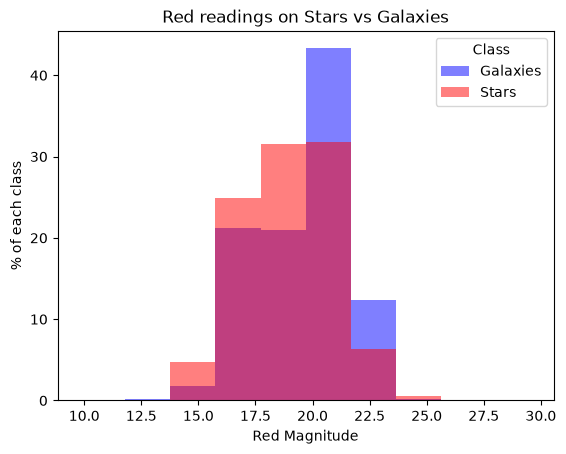

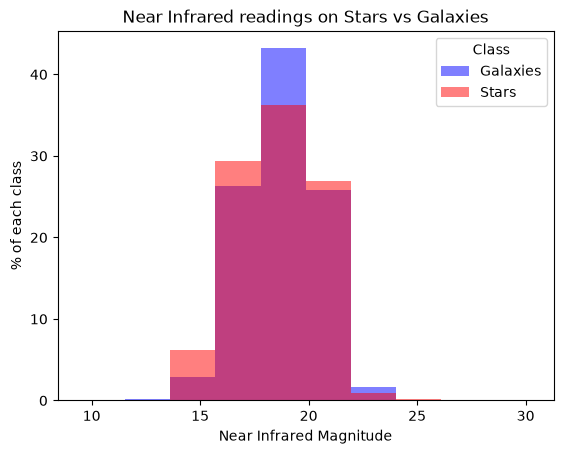

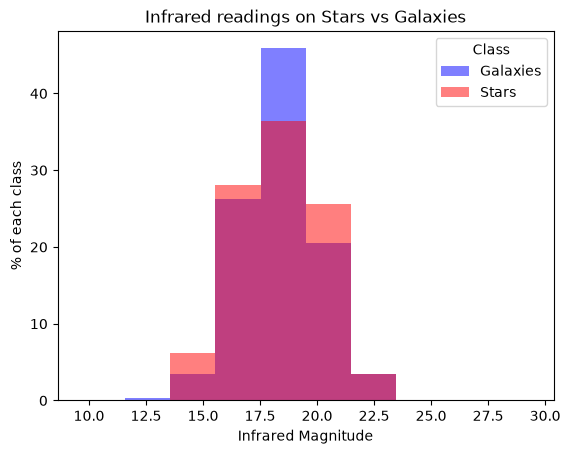

In [12]:
#Set weights because there are more galaxies in dataset
#Share a 100 percentage points across all the data
galaxyweights = np.full(len(galaxyonly), 100 / len(galaxyonly))
starweights = np.full(len(staronly), 100 / len(staronly))
#Preliminary graphs function
def histmaker(x):
    sharedrange = (min(galaxyonly[x].min(), staronly[x].min()), max(galaxyonly[x].max(), staronly[x].max()),)
    plt.hist(galaxyonly[x], bins=10, range=sharedrange, color = "blue", alpha = 0.5, label = "Galaxies", weights = galaxyweights)
    plt.hist(staronly[x], bins=10, range=sharedrange, color = "red", alpha = 0.5, label = "Stars", weights = starweights)
    plt.title(filtersname[x]+" readings on Stars vs Galaxies")
    plt.xlabel(filtersname[x]+ " Magnitude")
    plt.ylabel("% of each class")
    plt.legend(title= "Class")
    return plt.show()
for x in filters:
    histmaker(x)

In [13]:
#Confusion matrices
numruns = 5
uniqueids = df["obj_ID"].drop_duplicates()

filtersets = [(band,) for band in filters]
filtersets += list(combinations(filters, 2))
filtersets.append(tuple(filters))

results = []

for run in range(numruns):
    trainids = uniqueids.sample(frac=0.6, random_state=run)
    intraining = df["obj_ID"].isin(trainids)
    train = df.loc[intraining]
    test = df.loc[~intraining]

    actualstar = test["class"].to_numpy() == "STAR"

    for bands in filtersets:
        columns = list(bands)
        model = LogisticRegression()
        model.fit(train[columns], train["class"])
        guessedstar = model.predict(test[columns]) == "STAR"

        results.append({
            "run": run + 1,
            "model": "ugriz" if len(bands) == 5 else " + ".join(bands),
            "star_recall_pct": 100 * guessedstar[actualstar].mean(),
            "galaxies_mislabeled_pct": 100 * guessedstar[~actualstar].mean(),
        })

    print("Finished " + str(run + 1) + " of " + str(numruns) + " splits", flush=True)

simulationresults = pd.DataFrame(results)
summary = simulationresults.groupby("model", sort=False)[
    ["star_recall_pct", "galaxies_mislabeled_pct"]
].mean()

print("\nAverage confusion matrices across " + str(numruns) + " splits:")

for name, row in summary.iterrows():
    if name == "ugriz":
        title = "All five filters!!! [5]"
    else:
        bands = name.split(" + ")
        title = " + ".join(filtersname[band] for band in bands)
        if len(bands) == 1:
            title += "-only"
        title += " [" + str(len(bands)) + "]"

    print("\n" + title)

    galaxywrong = row["galaxies_mislabeled_pct"]
    starcorrect = row["star_recall_pct"]

    outcomes = [
        ("GALAXY", "GALAXY", 100 - galaxywrong),
        ("GALAXY", "STAR", galaxywrong),
        ("STAR", "GALAXY", 100 - starcorrect),
        ("STAR", "STAR", starcorrect),
    ]

    for actualclass, predictedclass, per100 in outcomes:
        if round(per100, 2) > 0:
            print("  Actual: " + actualclass
                  + " | Predicted: " + predictedclass
                  + " | Avg per 100: " + format(per100, ".2f"))

Finished 1 of 5 splits
Finished 2 of 5 splits
Finished 3 of 5 splits
Finished 4 of 5 splits
Finished 5 of 5 splits

Average confusion matrices across 5 splits:

Ultraviolet-only [1]
  Actual: GALAXY | Predicted: GALAXY | Avg per 100: 98.01
  Actual: GALAXY | Predicted: STAR | Avg per 100: 1.99
  Actual: STAR | Predicted: GALAXY | Avg per 100: 90.70
  Actual: STAR | Predicted: STAR | Avg per 100: 9.30

Green-only [1]
  Actual: GALAXY | Predicted: GALAXY | Avg per 100: 97.82
  Actual: GALAXY | Predicted: STAR | Avg per 100: 2.18
  Actual: STAR | Predicted: GALAXY | Avg per 100: 92.42
  Actual: STAR | Predicted: STAR | Avg per 100: 7.58

Red-only [1]
  Actual: GALAXY | Predicted: GALAXY | Avg per 100: 99.89
  Actual: GALAXY | Predicted: STAR | Avg per 100: 0.11
  Actual: STAR | Predicted: GALAXY | Avg per 100: 99.90
  Actual: STAR | Predicted: STAR | Avg per 100: 0.10

Near Infrared-only [1]
  Actual: GALAXY | Predicted: GALAXY | Avg per 100: 100.00
  Actual: STAR | Predicted: GALAXY | Av

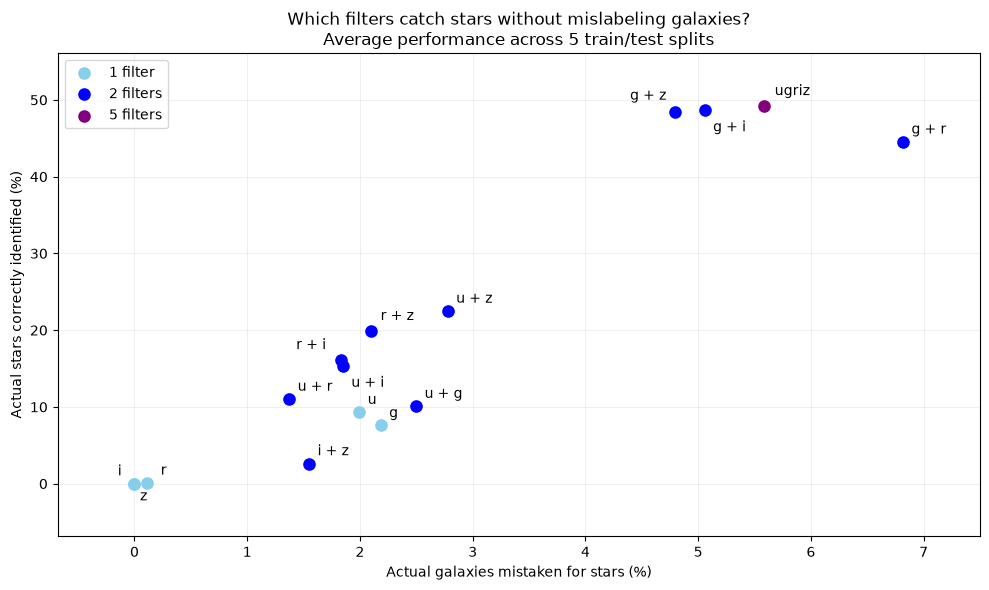

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = {1: "skyblue", 2: "blue", 5: "purple"}
showninlegend = set()

offsets = {
    "i": (-12, 6),
    "z": (4, -12),
    "r": (10, 6),
    "r + i": (-32, 8),
    "u + i": (6, -15),
    "r + z": (7, 8),
    "g + z": (-32, 9),
    "g + i": (6, -15),
    "ugriz": (8, 8),
}

for name, row in summary.iterrows():
    numfilters = 5 if name == "ugriz" else len(name.split(" + "))
    galaxyerror = row["galaxies_mislabeled_pct"]
    starrecall = row["star_recall_pct"]

    legendlabel = None
    if numfilters not in showninlegend:
        legendlabel = "1 filter" if numfilters == 1 else str(numfilters) + " filters"
        showninlegend.add(numfilters)

    ax.scatter(
        galaxyerror, starrecall,
        color=colors[numfilters], s=65, label=legendlabel,
    )
    ax.annotate(
        name, (galaxyerror, starrecall),
        xytext=offsets.get(name, (6, 6)),
        textcoords="offset points",
    )

ax.set_title(
    "Which filters catch stars without mislabeling galaxies?\n"
    "Average performance across " + str(numruns) + " train/test splits"
)
ax.set_xlabel("Actual galaxies mistaken for stars (%)")
ax.set_ylabel("Actual stars correctly identified (%)")
ax.margins(x=0.10, y=0.14)
ax.legend(loc="upper left")
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()